# Zernike aberration gallery: Z2 to Z16 from real lenses

The Fringe Zernike polynomials are the common language of wavefront
measurement: an interferometer, a Shack-Hartmann sensor or a lens design
program reports the wavefront of a lens as a list of coefficients. This
notebook goes the other way round. For each term from Z2 (tilt) to Z16
(secondary spherical aberration) it builds a small ray traced lens system
whose wavefront is, as far as possible, that one term, and shows the term
from both sides:

- **rays**: the layout of the lens, the ray fans (transverse ray
  aberrations over the pupil) and the rays around the focus in the y-z and
  x-z planes,
- **waves**: the wavefront (OPD map) with its Fringe Zernike spectrum, the
  point spread function (PSF) and the light through focus, in x-z and y-z
  sections and as a series of defocused spots.

The lenses are deliberately simple: an air spaced f/5 achromat that is
diffraction limited by itself, misaligned or combined with a plate, a
wedge or a window, a plano-convex singlet, and an aspheric singlet. Real
misalignments rarely give one term alone, so every entry also shows how
pure its wavefront is (the share of the term in the wavefront variance).

| Fringe | n, m | polynomial | name | lens situation here |
|---|---|---|---|---|
| Z2 | 1, 1 | $\rho\cos\theta$ | tilt x | thin wedge in front of the lens |
| Z3 | 1, −1 | $\rho\sin\theta$ | tilt y | lens decentred in y |
| Z4 | 2, 0 | $2\rho^2 - 1$ | defocus | image plane behind the focus |
| Z5 | 2, 2 | $\rho^2\cos 2\theta$ | astigmatism 0° | plane plate tilted about x in the converging beam |
| Z6 | 2, −2 | $\rho^2\sin 2\theta$ | astigmatism 45° | the plate tilted about the 45° diagonal |
| Z7 | 3, 1 | $(3\rho^3 - 2\rho)\cos\theta$ | coma x | flint element of the achromat tilted about y |
| Z8 | 3, −1 | $(3\rho^3 - 2\rho)\sin\theta$ | coma y | flint element decentred in y |
| Z9 | 4, 0 | $6\rho^4 - 6\rho^2 + 1$ | spherical aberration | plano-convex singlet, plane side first |
| Z10 | 3, 3 | $\rho^3\cos 3\theta$ | trefoil 0° | window bent by a three point mount |
| Z11 | 3, −3 | $\rho^3\sin 3\theta$ | trefoil 30° | the mount turned by 30° |
| Z12 | 4, 2 | $(4\rho^4 - 3\rho^2)\cos 2\theta$ | secondary astigmatism 0° | figure error of a window |
| Z13 | 4, −2 | $(4\rho^4 - 3\rho^2)\sin 2\theta$ | secondary astigmatism 45° | the same, turned by 45° |
| Z14 | 5, 1 | $(10\rho^5 - 12\rho^3 + 3\rho)\cos\theta$ | secondary coma x | Schmidt type corrector decentred in x |
| Z15 | 5, −1 | $(10\rho^5 - 12\rho^3 + 3\rho)\sin\theta$ | secondary coma y | the corrector decentred in y |
| Z16 | 6, 0 | $20\rho^6 - 30\rho^4 + 12\rho^2 - 1$ | secondary spherical aberration | fast singlet with a fourth order asphere |

Notebook 15 shows the pure Fringe Zernikes and their PSFs, notebook 16 the
bases themselves, notebook 19 the ray tracer and notebook 21 the hand-off
from rays to waves used here.

**Conventions.** Fringe Zernikes as in `bases.fringe_zernike()` (peak
value 1 at the rim, $\theta$ counted from x towards y), coefficients in
waves of the OPD. The OPD is the optical path of a ray minus that of the
chief ray (pyoptics convention, phase $= +2\pi\,\mathrm{OPD}/\lambda$), so
an image plane behind the focus gives OPD < 0 at the rim. The ray
aberration is $\varepsilon = (R/n')\,\partial W/\partial Y$ (Welford): in
units of $\lambda/\mathrm{NA}$, the ray fans are the slopes of the wavefront
in waves per pupil radius, $\varepsilon/(\lambda/\mathrm{NA}) = \partial
W/\partial P$. All image space plots use the units $\lambda/\mathrm{NA}$
across and $\lambda/\mathrm{NA}^2$ along the axis, so that lenses of
different aperture can be compared; the Airy radius is $0.61$ and the
Rayleigh depth of focus $\pm 0.5$ in these units.

**Equal RMS.** Every lens is set up (by one parameter: a decentre, a tilt,
an aperture, an amplitude) so that its main term has the same RMS
wavefront of 0.15 waves. By Maréchal's approximation $S \approx
e^{-(2\pi\sigma)^2}$ all PSFs then have about the same Strehl ratio of 0.41,
and the differences between the terms show in the shapes alone. The two
tilts are the exception: a tilt only moves the image, here by one
$\lambda/\mathrm{NA}$ (coefficient 1 wave).

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colormaps
from matplotlib.colors import ListedColormap
from scipy.optimize import brentq, fsolve

from pyoptics import raytrace as rt
from pyoptics.bases import fringe_zernike, fringe_to_n_m
from pyoptics.imaging import get_psf
from pyoptics.propagators import rayleigh_sommerfeld_I_TF_planes

plt.rcParams.update({"figure.dpi": 72, "font.size": 10, "axes.titlesize": 10,
                     "figure.facecolor": "white", "axes.facecolor": "#fcfcfb",
                     "savefig.facecolor": "white", "image.origin": "lower",
                     "axes.spines.top": False, "axes.spines.right": False})
t_start = time.time()

# intensity colour map on white: reversed magma, its pale low end faded to white
t = np.linspace(0, 1, 256)[:, None]
light = ListedColormap(1 - (1 - colormaps["magma_r"](t[:, 0])[:, :3])*np.clip(t/0.15, 0, 1), name="light")

WL = 550e-6                                  # mm
BK7, F2 = (1.5168, 64.17), (1.6200, 36.37)   # (n_d, V_d)
SIGMA = 0.15                                 # RMS of the main term, waves
NAMES = {2: "tilt x", 3: "tilt y", 4: "defocus", 5: "astigmatism 0°", 6: "astigmatism 45°",
         7: "coma x", 8: "coma y", 9: "spherical aberration", 10: "trefoil 0°", 11: "trefoil 30°",
         12: "secondary astigmatism 0°", 13: "secondary astigmatism 45°", 14: "secondary coma x",
         15: "secondary coma y", 16: "secondary spherical aberration"}
J = np.arange(1, 17)


def rms_factor(j):
    # RMS of Z_j over the unit disk
    n, m = fringe_to_n_m(j)
    return np.sqrt((1 + (m == 0))/(2*(n + 1)))


def target(j):
    # coefficient with the RMS SIGMA (tilts: 1 wave, a shift of lambda/NA)
    return 1.0 if j in (2, 3) else SIGMA/rms_factor(j)


print("targets (waves): " + ", ".join("Z{} {:.2f}".format(j, target(j)) for j in range(2, 17)))

targets (waves): Z2 1.00, Z3 1.00, Z4 0.26, Z5 0.37, Z6 0.37, Z7 0.42, Z8 0.42, Z9 0.34, Z10 0.42, Z11 0.42, Z12 0.47, Z13 0.47, Z14 0.52, Z15 0.52, Z16 0.40


## 1. The terms on their own

For reference, the fifteen wavefronts with the RMS of 0.15 waves (tilts:
1 wave) and their PSFs from `imaging.get_psf()`, square root of the
intensity so that the faint rings show. These are the targets the lenses
below are set up for.

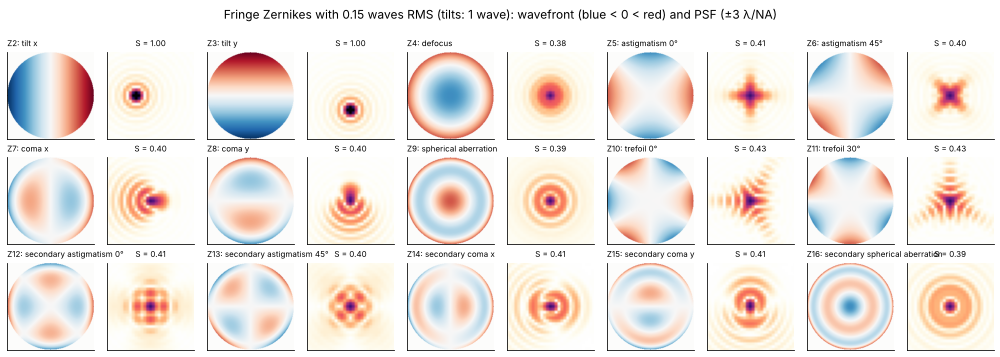

In [2]:
p = np.linspace(-1, 1, 201)
PX, PY = np.meshgrid(p, p)
disk = PX**2 + PY**2 <= 1
u_psf = 0.2*(np.arange(160) - 80)                      # lambda/NA
NA_ref = 0.1
psf_ideal = {}
fig, axes = plt.subplots(3, 10, figsize=(14, 5))
for k, j in enumerate(range(2, 17)):
    c = target(j)
    W = np.where(disk, c*fringe_zernike(j, PX, PY), np.nan)
    ax = axes[k//5, 2*(k % 5)]
    v = 1.6*c if j > 3 else c
    ax.imshow(W, extent=[-1, 1, -1, 1], cmap="RdBu_r", vmin=-v, vmax=v)
    ax.set_title("Z{}: {}".format(j, NAMES[j]), fontsize=8, loc="left")
    E = get_psf(u_psf*WL/NA_ref, u_psf*WL/NA_ref, NA_ref, 2*np.pi/WL,
                phase=lambda P_x, P_y, j=j, c=c: 2*np.pi*c*fringe_zernike(j, P_x, P_y))
    psf_ideal[j] = np.abs(E)**2
    ax = axes[k//5, 2*(k % 5) + 1]
    ax.imshow(np.sqrt(psf_ideal[j]), extent=[u_psf[0], u_psf[-1]]*2, cmap=light, vmin=0, vmax=0.8)
    ax.set_xlim(-3, 3), ax.set_ylim(-3, 3)
    ax.set_title("S = {:.2f}".format(psf_ideal[j].max()), fontsize=8)
for ax in axes.flat:
    ax.set_xticks([]), ax.set_yticks([])
fig.suptitle("Fringe Zernikes with 0.15 waves RMS (tilts: 1 wave): wavefront (blue < 0 < red) and PSF "
             "(±3 λ/NA)", y=0.995)
plt.tight_layout()

## 2. Tools: one figure per term

The helpers below analyse a traced system:

- `refocus()` moves the image plane to the focus with Z4 = 0 (the best
  focus in the sense of the smallest RMS wavefront),
- `analyse()` fits Fringe Zernikes to the OPD (`System.zernike()`) and fixes
  the reference point in the image plane. Lens design programs refer the
  OPD to the chief ray. For a comatic beam the chief ray is not the centre
  of the light, and the Fringe coma $3\rho^3 - 2\rho$ contains a tilt that
  moves the reference to the centre of the diffraction pattern. Here, the
  reference point of every term but the tilts is the point that makes
  Z2 = Z3 = 0. For the two tilts it is the image point of the perfect
  lens: tilt is the displacement of the image, $\Delta = c\,\lambda/\mathrm{NA}$
  for the coefficient $c$,
- `gallery()` draws the figure: layout, Zernike spectrum, OPD map, ray fans
  (traced: solid; slope of the main Zernike term alone: dashed), the PSF in
  the image plane (`System.psf()`), rays and waves in the y-z and x-z planes
  around the focus (field from `System.psf()`, carried through focus with
  the angular spectrum, `rayleigh_sommerfeld_I_TF_planes()`, intensity on a
  logarithmic scale over 30 dB, sections through the brightest point) and
  seven spots through focus (square root of the intensity, all scaled to
  the brightest of them).

In [3]:
def chief_point(s):
    b = s.trace_pupil(0.0, 0.0, 0.0)
    return s.to_image_frame(b.points[-1])[0, :2]


def image_na(s):
    # n' |d - d_chief| of four rim rays
    b = s.trace_pupil(0.0, np.array([0.0, 0.0, 1.0, 0.0, -1.0]), np.array([0.0, 1.0, 0.0, -1.0, 0.0]))
    d = s.to_image_frame(b.points[-1], b.directions[-1])[1]
    return s.n[-1]*np.mean(np.linalg.norm(d[1:, :2] - d[0, :2], axis=1))


def refocus(s, iterations=2):
    # image plane at Z4 = 0 (secant steps, Z4 is nearly linear in the image distance)
    for _ in range(iterations):
        d0 = s.surfaces[-1].thickness
        c0 = s.zernike(0.0, 16, 32)[3]
        c1 = s.with_image_distance(d0 + 0.01).zernike(0.0, 16, 32)[3]
        s = s.with_image_distance(d0 - 0.01*c0/(c1 - c0))
    return s


def analyse(s, reference="best", N=48):
    # Fringe Zernikes about the reference point: "best" (Z2 = Z3 = 0) or "nominal" (x = y = 0)
    c = s.zernike(0.0, 16, N)
    NA = image_na(s)
    chief = chief_point(s)
    ref = chief + c[1:3]*WL/NA if reference == "best" else np.zeros(2)
    c[1:3] += (chief - ref)*NA/WL
    return c, ref, NA


def coefficient(s, j, reference="best"):
    return analyse(s, reference, 32)[0][j - 1]


def share(c, j):
    # share of Z_j in the wavefront variance (piston excluded)
    var = (c[1:]*np.array([rms_factor(i) for i in J[1:]]))**2
    return var[j - 2]/var.sum()


def fans(s, ref, p):
    out = []
    for px, py in ((0*p, p), (p, 0*p)):
        b = s.trace_pupil(0.0, px, py)
        P, d = s.to_image_frame(b.points[-1], b.directions[-1])
        out.append((P[:, :2] - ref, d[:, :2]/d[:, 2:]))
    return out  # [(positions, slopes) tangential, sagittal]


def zernike_slopes(j, c, px, py, h=1e-6):
    # dW/dP_x, dW/dP_y of c Z_j (waves per pupil radius)
    return (c*(fringe_zernike(j, px + h, py) - fringe_zernike(j, px - h, py))/(2*h),
            c*(fringe_zernike(j, px, py + h) - fringe_zernike(j, px, py - h))/(2*h))


u = 0.25*(np.arange(128) - 64)        # image plane grid, lambda/NA
zu = np.linspace(-4, 4, 161)          # through focus, lambda/NA**2
z_spots = np.linspace(-3, 3, 7)
RESULTS = {}


def gallery(j, s, situation, knob, reference="best", plane="yz", draw_kw=None):
    c, ref, NA = analyse(s, reference)
    lam_na, lam_na2 = WL/NA, WL/NA**2
    strehl = s.strehl(0.0, 64)
    RESULTS[j] = dict(situation=situation, knob=knob, c=c[j - 1], share=share(c, j), strehl=strehl, NA=NA)

    fig = plt.figure(figsize=(13, 10.8))
    gs = fig.add_gridspec(4, 4, height_ratios=[1.05, 1, 1, 0.62], hspace=0.45, wspace=0.42,
                          left=0.06, right=0.98, top=0.91, bottom=0.03)
    fig.suptitle("Z{}: {}  ({}; {})".format(j, NAMES[j], situation, knob), fontsize=13, x=0.05, y=0.985, ha="left")

    # layout:
    ax = fig.add_subplot(gs[0, :3])
    s.draw(ax, fields=[0.0], n_rays=9, plane=plane, **(draw_kw or {}))
    data = np.concatenate([line.get_xydata() for line in ax.get_lines()[:-1]])  # without the axis line
    lo, hi = np.nanmin(data, axis=0), np.nanmax(data, axis=0)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlim(lo[0] - 0.03*(hi[0] - lo[0]), hi[0] + 0.03*(hi[0] - lo[0]))
    ax.set_ylim(1.15*lo[1], 1.15*hi[1])
    ax.set_xlabel("z (mm)"), ax.set_ylabel(plane[0] + " (mm)")
    ax.set_title("layout, {}-z plane (NA {:.3f})".format(plane[0], NA), loc="left")

    # Zernike spectrum:
    ax = fig.add_subplot(gs[0, 3])
    colors = ["C3" if i == j else "0.55" for i in J[1:]]
    ax.bar(J[1:], c[1:], color=colors)
    ax.axhline(0, color="0.3", lw=0.6)
    ax.set_xticks(J[1:])
    ax.tick_params(axis="x", labelsize=7)
    ax.set_xlabel("Fringe index j"), ax.set_ylabel("coefficient (waves)")
    ax.set_title("Z{} = {:+.3f} waves, {:.0f} % of the variance\nStrehl ratio {:.2f}".format(
        j, c[j - 1], 100*share(c, j), strehl), loc="left")

    # OPD map about the reference point:
    m = s.opd(0.0, 96)
    MX, MY = np.meshgrid(m.px, m.py)
    k_tilt = (chief_point(s) - ref)*NA/WL
    W = m.W + k_tilt[0]*MX + k_tilt[1]*MY
    W = W - np.nanmean(W)
    ax = fig.add_subplot(gs[1, 0])
    v = np.nanmax(np.abs(W))
    im = ax.imshow(W, extent=[-1, 1, -1, 1], cmap="RdBu_r", vmin=-v, vmax=v)
    ax.contour(m.px, m.py, W, levels=np.linspace(-v, v, 11), colors="k", linewidths=0.4)
    fig.colorbar(im, ax=ax, shrink=0.85, pad=0.03)
    ax.set_xlabel("$P_x$"), ax.set_ylabel("$P_y$")
    ax.set_title("wavefront (waves), PV {:.2f}".format(np.nanmax(W) - np.nanmin(W)), loc="left")

    # ray fans:
    pf = np.linspace(-1, 1, 81)
    (Pt, _), (Ps, _) = fans(s, ref, pf)
    for k, (P, name, lab) in enumerate(((Pt, "tangential fan ($P_x$ = 0)", "$P_y$"),
                                        (Ps, "sagittal fan ($P_y$ = 0)", "$P_x$"))):
        ax = fig.add_subplot(gs[1, 1 + k])
        px, py = (0*pf, pf) if k == 0 else (pf, 0*pf)
        gx, gy = zernike_slopes(j, c[j - 1], px, py)
        ax.plot(pf, P[:, 1]/lam_na, "C0", label=r"$\varepsilon_y$")
        ax.plot(pf, P[:, 0]/lam_na, "C1", label=r"$\varepsilon_x$")
        ax.plot(pf, gy, "C0--", lw=0.9)
        ax.plot(pf, gx, "C1--", lw=0.9)
        ax.axhline(0, color="0.6", lw=0.6), ax.axvline(0, color="0.6", lw=0.6)
        ax.set_xlabel(lab), ax.set_ylabel(r"$\varepsilon$ (λ/NA)")
        ax.set_title(name, loc="left")
        lim = max(1.0, 1.1*np.nanmax(np.abs(P/lam_na)))
        ax.set_ylim(-lim, lim)
        ax.legend(fontsize=8, loc="best")

    # waves: field in the image plane, through focus
    x = u*lam_na
    E0 = s.psf(x, x, 0.0, 64)
    E = rayleigh_sommerfeld_I_TF_planes(E0, x, x, zu*lam_na2, WL)[0]
    off = (chief_point(s) - ref)/lam_na          # grid relative to the reference point
    ux, uy = u + off[0], u + off[1]
    I = np.abs(E)**2
    _, iy, ix = np.unravel_index(np.argmax(I), I.shape)   # sections through the brightest point
    ax = fig.add_subplot(gs[1, 3])
    I0 = np.abs(E0)**2
    ax.imshow(np.sqrt(I0/I0.max()), extent=[ux[0], ux[-1], uy[0], uy[-1]], cmap=light, vmin=0, vmax=1,
              interpolation="bicubic")
    ax.set_xlim(-4, 4), ax.set_ylim(-4, 4)
    ax.plot(0, 0, "+", color="C0", ms=10)
    ax.set_xlabel("x (λ/NA)"), ax.set_ylabel("y (λ/NA)")
    ax.set_title("PSF (square root), peak {:.2f}".format(I0.max()), loc="left")
    RESULTS[j]["psf"] = (ux, uy, I0)

    # rays and waves around the focus:
    zz = np.array([zu[0], zu[-1]])
    pr = np.linspace(-1, 1, 15)
    (Pt, tt), (Ps, ts) = fans(s, ref, pr)
    for k, (axis, P, tsl, S, uu) in enumerate(((1, Pt, tt, I[:, :, ix], uy), (0, Ps, ts, I[:, iy, :], ux))):
        name = "yx"[k]
        ax = fig.add_subplot(gs[2, 2*k])
        for p0, sl in zip(P[:, axis]/lam_na, tsl[:, axis]/NA):
            ax.plot(zz, p0 + sl*zz, color="C0", lw=0.6)
        ax.set_xlim(zz), ax.set_ylim(-5, 5)
        ax.set_xlabel("z (λ/NA²)"), ax.set_ylabel(name + " (λ/NA)")
        ax.set_title("rays, {}-z plane ({} fan)".format(name, "tangential" if k == 0 else "sagittal"),
                     loc="left")
        ax = fig.add_subplot(gs[2, 2*k + 1])
        ax.imshow(10*np.log10(S.T/I.max() + 1e-12), extent=[zu[0], zu[-1], uu[0], uu[-1]], aspect="auto",
                  cmap=light, vmin=-30, vmax=0, interpolation="bicubic")
        ax.set_xlim(zz), ax.set_ylim(-5, 5)
        ax.set_xlabel("z (λ/NA²)"), ax.set_ylabel(name + " (λ/NA)")
        ax.set_title("wave, {}-z section (log, 30 dB)".format(name), loc="left")

    # through focus spots:
    sub = gs[3, :].subgridspec(1, len(z_spots), wspace=0.08)
    k_spots = [np.argmin(np.abs(zu - z)) for z in z_spots]
    I_max = max(I[k].max() for k in k_spots)
    for n_ax, (k, z) in enumerate(zip(k_spots, z_spots)):
        ax = fig.add_subplot(sub[0, n_ax])
        ax.imshow(np.sqrt(I[k]/I_max), extent=[ux[0], ux[-1], uy[0], uy[-1]], cmap=light, vmin=0, vmax=0.9,
                  interpolation="bicubic")
        ax.set_xlim(-5, 5), ax.set_ylim(-5, 5)
        ax.set_xticks([]), ax.set_yticks([])
        ax.set_title("z = {:+.0f} λ/NA²".format(z), fontsize=9)
    return fig


def tune(build, j, lo, hi, reference="best"):
    # parameter in [lo, hi] for |Z_j| = target(j)
    x = brentq(lambda x: abs(coefficient(build(x), j, reference)) - target(j), lo, hi, xtol=1e-9)
    return x, build(x)

## 3. The base lens: an air spaced achromat

Most entries start from one lens: a crown and flint achromat designed (as
thin lenses) for 100 mm focal length at f/5, for 550 nm: the cemented
doublet of notebook 19 with its elements 0.1 mm apart. As a thick lens its
focal length is 103 mm, the image side NA 0.097. The rear radius of the flint corrects the
axial colour (F and C focus together), the front radius of the crown the
spherical aberration (Z9 = 0 at the best focus). The aperture stop is
5 mm in front of the lens and stays in place when elements are misaligned.
The residue is a little secondary spherical aberration (Z16 ≈ 0.01 waves),
the lens is diffraction limited.

R1 = 47.245 mm, R2 = -42.556 mm, R3 = -567.152 mm, focal length 103.38 mm, back focal distance 98.292 mm
NA 0.0972, Strehl 0.9992, largest coefficient Z16 = +0.0118 waves


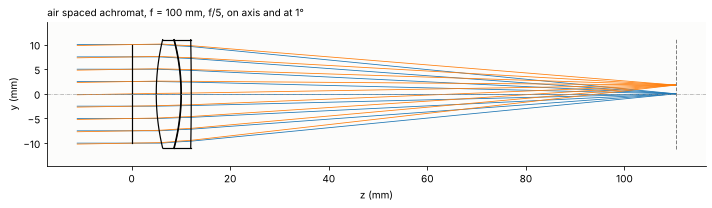

In [4]:
f, EPR, GAP = 100.0, 10.0, 0.1
phi1, phi2 = BK7[1]/(BK7[1] - F2[1])/f, -F2[1]/(BK7[1] - F2[1])/f


def achromat_surfaces(c1, c3, decenter=(0.0, 0.0), flint_decenter=(0.0, 0.0), flint_tilt=(0.0, 0.0, 0.0)):
    c2 = c1 - phi1/(BK7[0] - 1)
    return [rt.Surface(1/c1, 5.0, material=BK7, semi_diameter=11.0, decenter=decenter, label="BK7"),
            rt.Surface(1/c2, GAP, n_after=1.0, semi_diameter=11.0, decenter=decenter),
            rt.Surface(1/c2, 2.0, material=F2, semi_diameter=11.0, decenter=np.add(decenter, flint_decenter),
                       tilt=flint_tilt, label="F2"),
            rt.Surface(1/c3, 95.0, n_after=1.0, semi_diameter=11.0, decenter=np.add(decenter, flint_decenter),
                       tilt=flint_tilt)]


def stop(d=5.0):
    return rt.Surface(np.inf, d, semi_diameter=EPR, label="stop")


def colour_corrected(c1):
    # c3 for equal F and C foci
    build = lambda c3: rt.System([stop()] + achromat_surfaces(c1, c3), 0, WL)
    c2 = c1 - phi1/(BK7[0] - 1)
    c3_thin = c2 - phi2/(F2[0] - 1)
    focus = lambda c3, wl: build(c3).with_wavelength(wl).paraxial().image_distance
    return brentq(lambda c3: focus(c3, 486.1327e-6) - focus(c3, 656.2725e-6), c3_thin - 2e-3, c3_thin + 2e-3)


def z9_of(R1):
    c1 = 1/R1
    s = rt.System([stop()] + achromat_surfaces(c1, colour_corrected(c1)), 0, WL).at_paraxial_focus()
    return refocus(s).zernike(0.0, 16, 32)[8]


R1 = brentq(z9_of, 40.0, 60.0)
C1, C3 = 1/R1, colour_corrected(1/R1)
nominal = refocus(rt.System([stop()] + achromat_surfaces(C1, C3), 0, WL).at_paraxial_focus())
BACK = nominal.surfaces[-1].thickness


def achromat(before=(), after=None, back=None, **misalignment):
    # stop, optional elements in front, the achromat, optional elements behind (they take the last
    # space: after = (distance from the lens, [surfaces]), the last surface carries the image distance)
    surfaces = [stop()] + list(before) + achromat_surfaces(C1, C3, **misalignment)
    if after is not None:
        d, extra = after
        surfaces[-1].thickness = d
        surfaces += extra
    s = rt.System(surfaces, 0, WL)
    if back is not None:
        s = s.with_image_distance(back)
    return s


print("R1 = {:.3f} mm, R2 = {:.3f} mm, R3 = {:.3f} mm, focal length {:.2f} mm, back focal distance {:.3f} mm".format(
    R1, 1/(C1 - phi1/(BK7[0] - 1)), 1/C3, nominal.paraxial().efl, BACK))
c, ref, NA = analyse(nominal)
print("NA {:.4f}, Strehl {:.4f}, largest coefficient Z{} = {:+.4f} waves".format(
    NA, nominal.strehl(0.0, 64), np.argmax(np.abs(c[1:])) + 2, c[1:][np.argmax(np.abs(c[1:]))]))
fig, ax = plt.subplots(figsize=(10, 3))
nominal.draw(ax, fields=[0.0, np.radians(1.0)], n_rays=9)
ax.set_title("air spaced achromat, f = 100 mm, f/5, on axis and at 1°", loc="left")
ax.set_xlabel("z (mm)"), ax.set_ylabel("y (mm)")
plt.tight_layout()

## 4. Tilt (Z2, Z3)

Tilt of the wavefront moves the image sideways and does nothing else: the
PSF is a perfect Airy pattern in the wrong place, and the ray fans are
constant, all rays are displaced by the same amount. The Strehl ratio
(with the tilt removed, as `System.strehl()` does) stays 1. In an imaging
system, tilt that varies over the field is distortion; in an alignment it
is the line of sight error.

**Z2: a thin wedge.** A wedge of angle $\alpha$ in a collimated beam
deviates it by $\delta = (n - 1)\alpha$, the focus moves by $f\delta$. One
wave of Z2 is a shift of $\lambda/\mathrm{NA} = 5.7$ µm, i.e. a deviation of
55 µrad: a wedge of about 20 arc seconds, the tolerance class of a good
window. The wedge here is turned so that it deviates in x; the layout is
drawn in the x-z plane.

image shift 5.68 µm, f (n - 1) alpha = 5.68 µm, wl/NA = 5.66 µm


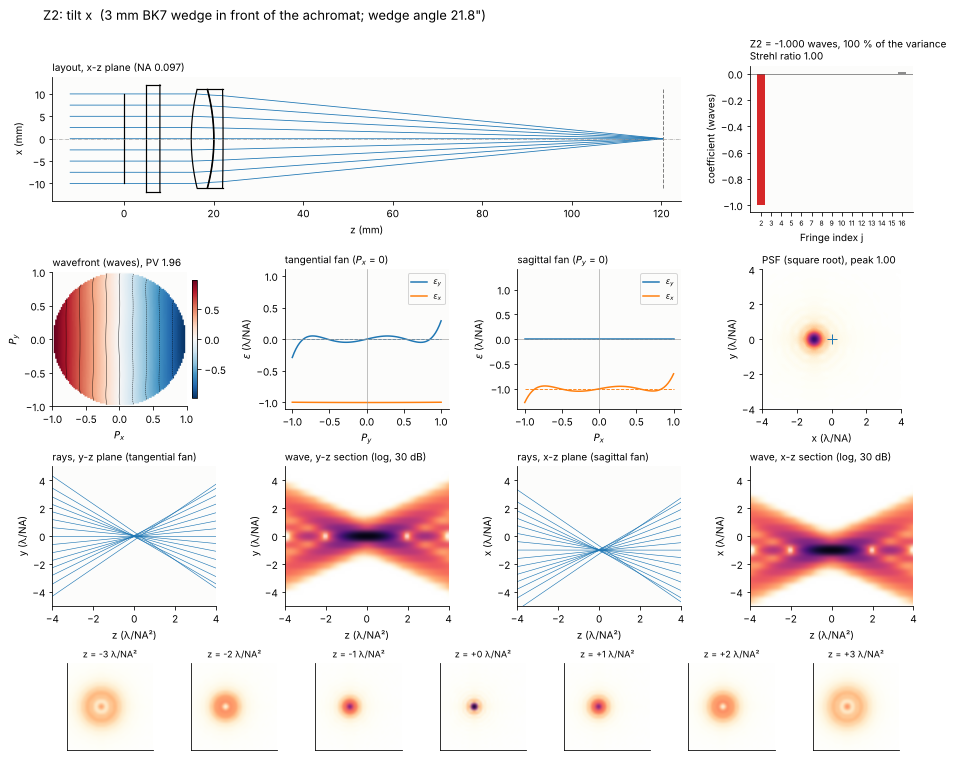

In [5]:
def wedge(alpha):
    w = [rt.Surface(np.inf, 3.0, material=BK7, semi_diameter=12.0, label="wedge"),
         rt.Surface(np.inf, 7.0, n_after=1.0, semi_diameter=12.0, tilt=(0.0, alpha, 0.0))]
    return achromat(before=w, back=BACK)


alpha, s = tune(wedge, 2, 1e-6, 1e-3, reference="nominal")
fig = gallery(2, s, "3 mm BK7 wedge in front of the achromat", "wedge angle {:.1f}\"".format(np.degrees(alpha)*3600),
              reference="nominal", plane="xz")
print("image shift {:.2f} µm, f (n - 1) alpha = {:.2f} µm, wl/NA = {:.2f} µm".format(
    -chief_point(s)[0]*1e3, s.paraxial().efl*(rt.abbe_dispersion(550.0, *BK7) - 1)*alpha*1e3,
    WL/RESULTS[2]["NA"]*1e3))

**Z3: a decentred lens.** A lens decentred by $\Delta y$ in a collimated
beam takes its focus along: the image moves by $\Delta y$. One wave of tilt
needs a decentre of only 5.7 µm. Because the achromat is free of spherical
aberration, decentring the whole lens against the stop changes nothing
else; compare coma (Z8), where only one element is decentred.

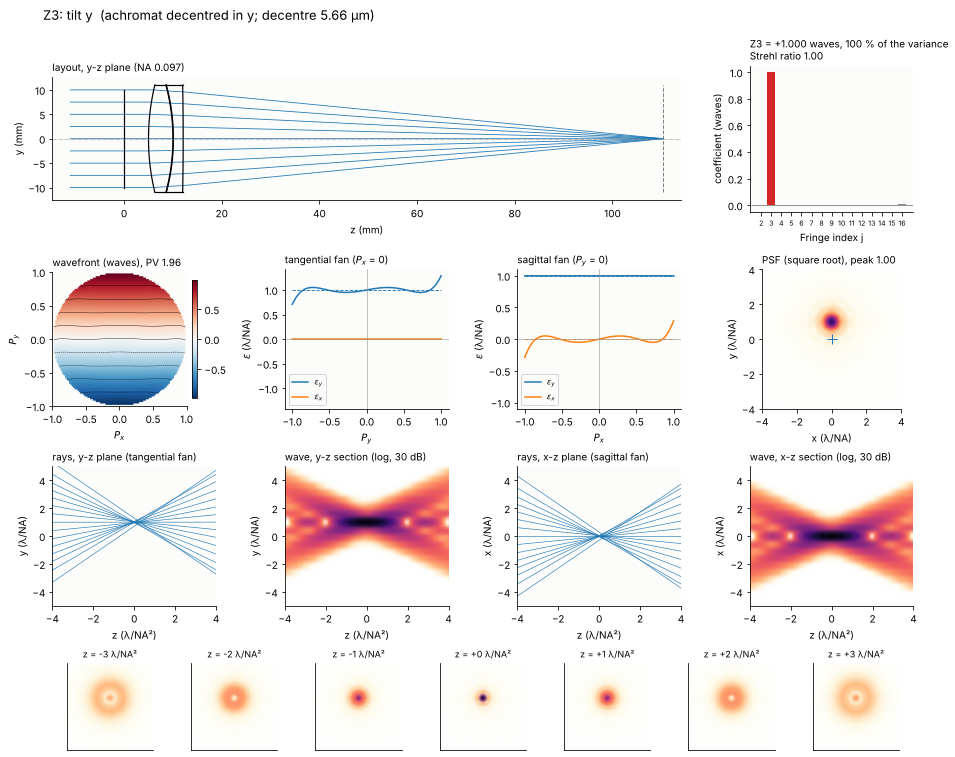

In [6]:
dy, s = tune(lambda d: achromat(decenter=(0.0, d), back=BACK), 3, 1e-5, 0.1, reference="nominal")
fig = gallery(3, s, "achromat decentred in y", "decentre {:.2f} µm".format(dy*1e3), reference="nominal")

## 5. Defocus (Z4)

An image plane at the distance $\Delta z$ from the focus sees the wavefront
$W = -\tfrac{1}{2}\,\mathrm{NA}^2 \Delta z\,\rho^2$ (paraxially), i.e.
$Z4 = -\mathrm{NA}^2\Delta z/(4\lambda)$. 0.26 waves of defocus is a plane
1.04 λ/NA² = 60 µm behind the focus. The ray fans are straight lines
through the origin (the rays cross the axis in front of the plane), the
spot through focus is symmetric about the focus: defocus is the one term a
refocus removes completely. The x-z and y-z sections show the focus moved
by the defocus to the left.

NA**2 dz/(4 wl) = 0.259 waves


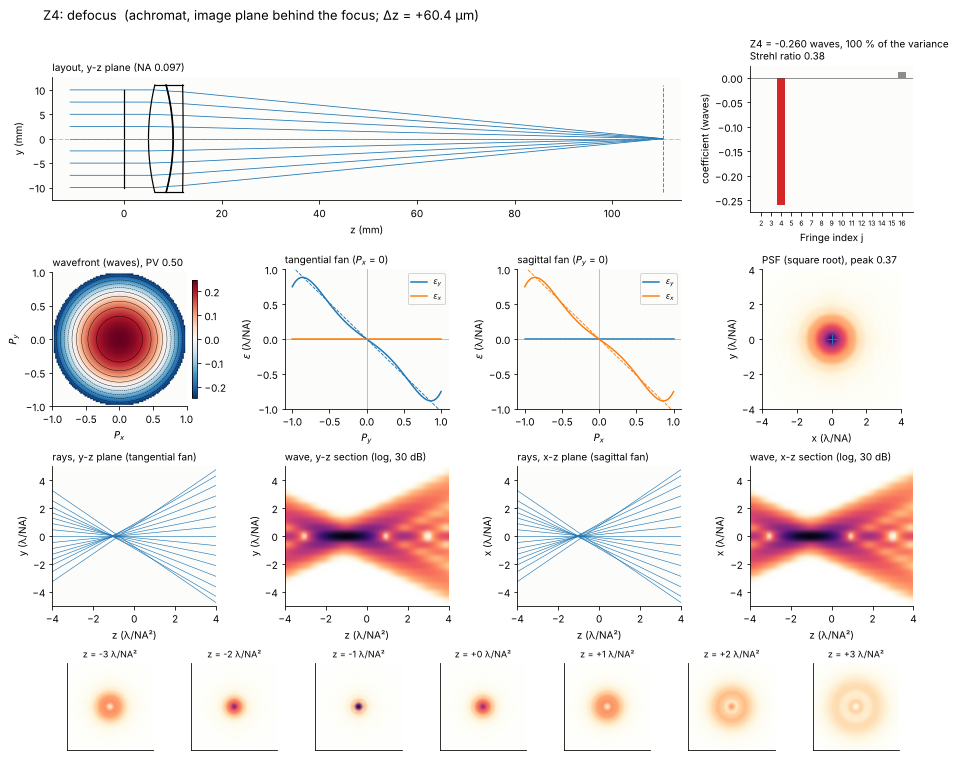

In [7]:
dz, s = tune(lambda d: achromat(back=BACK + d), 4, 1e-4, 1.0)
fig = gallery(4, s, "achromat, image plane behind the focus", "Δz = {:+.1f} µm".format(dz*1e3))
print("NA**2 dz/(4 wl) = {:.3f} waves".format(RESULTS[4]["NA"]**2*dz/(4*WL)))

## 6. Astigmatism (Z5, Z6)

**Z5: a tilted plane plate in a converging beam.** A plane parallel plate
in a converging beam shifts the focus by $t(n - 1)/n$ and adds a little
spherical aberration. Tilted, it focuses the rays in the plane of the tilt
(here the y-z plane, tangential) behind those in the perpendicular plane
(sagittal). The difference is $\Delta z \approx t\theta^2 (n^2 -
1)/n^3$ for small tilts $\theta$ (Smith; notebook 19 checks the exact
formula). Beam splitter plates, filters and windows in front of a camera
do this. The plate is 2 mm thick, 50 mm behind the lens; the image plane is
moved to the medial focus between the two line foci (Z4 = 0). The tilt
also brings a little coma (Z8) and an image shift (removed with the
reference point).

The ray fans are straight lines of opposite slope in the two sections. In
the x-z and y-z sections the two line foci lie on opposite sides of the
medial focus: the spot is a line in y on one side, a cross shaped spot of
about equal width in the middle and a line in x on the other side.

focal difference: t theta**2 (n**2 - 1)/n**3 = 82.5 µm, i.e. 1.42 lambda/NA**2


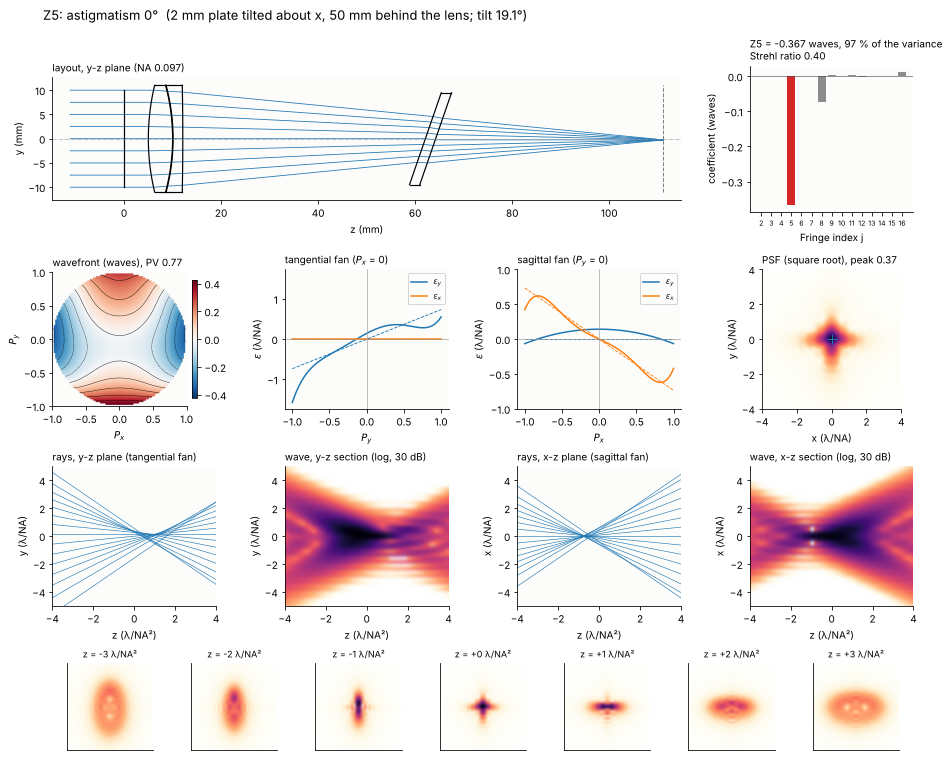

In [8]:
T_PLATE, D_PLATE = 2.0, 50.0


def plate(theta, azimuth=0.0):
    # normal of the plate tilted by theta towards the azimuth (0: tilt about x, in the y-z plane)
    a_y = np.arcsin(np.sin(theta)*np.sin(azimuth))
    a_x = np.arcsin(np.sin(theta)*np.cos(azimuth)/np.cos(a_y))
    tilt = (a_x, a_y, 0.0)
    surfaces = [rt.Surface(np.inf, T_PLATE/np.cos(theta), material=BK7, semi_diameter=10.0, tilt=tilt,
                           label="plate"),
                rt.Surface(np.inf, BACK - D_PLATE, n_after=1.0, semi_diameter=10.0, tilt=tilt)]
    return refocus(achromat(after=(D_PLATE, surfaces)))


theta, s = tune(plate, 5, 0.01, 0.8)
fig = gallery(5, s, "2 mm plate tilted about x, 50 mm behind the lens", "tilt {:.1f}°".format(np.degrees(theta)))
n_d = rt.abbe_dispersion(550.0, *BK7)
print("focal difference: t theta**2 (n**2 - 1)/n**3 = {:.1f} µm, i.e. {:.2f} lambda/NA**2".format(
    T_PLATE*theta**2*(n_d**2 - 1)/n_d**3*1e3, T_PLATE*theta**2*(n_d**2 - 1)/n_d**3/(WL/RESULTS[5]["NA"]**2)))

**Z6: the plate tilted about the diagonal.** The same plate tilted towards
the 45° direction (about an axis at −45°) gives the same astigmatism
turned by 45°: $\rho^2\sin 2\theta = 2P_xP_y$. Now the line foci are
diagonal. In the tangential fan ($P_x$ = 0) the rays leave the y-z plane
($\varepsilon_x \neq 0$) but stay at $\varepsilon_y = 0$; the x-z and y-z
sections look the same, the foci lie on the diagonals. Comparing the two
fans tells Z5 from Z6.

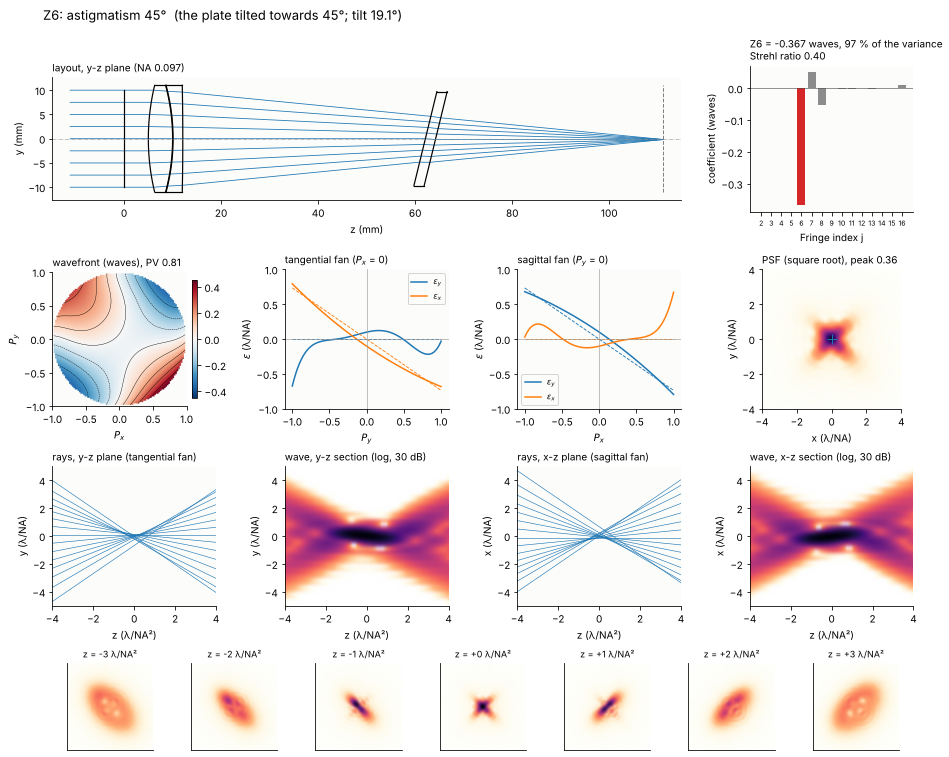

In [9]:
theta, s = tune(lambda t: plate(t, np.pi/4), 6, 0.01, 0.8)
fig = gallery(6, s, "the plate tilted towards 45°", "tilt {:.1f}°".format(np.degrees(theta)))

## 7. Coma (Z7, Z8)

The achromat corrects its spherical aberration by balancing the crown
against the flint, each of which alone has several waves of it. Decentre
or tilt one of them and the balance breaks asymmetrically: the result is
coma, proportional to the misalignment. This is why coma is the signature
of a decentred element in a lens and the term that alignment by
decentring ("centring") minimizes (Thompson's nodal aberration theory
describes the field dependence). By contrast, decentring the whole lens
(Z3 above) gives no coma, because the lens as a whole has no spherical
aberration.

The comatic PSF is the comet with its tail along the direction of the
coma. The tangential fan is a parabola (the cubic $3\rho^3$ derivative),
the sagittal fan has the same parabola in the other component with a third
of the curvature ($\varepsilon_y \propto P_x^2$). Through focus the comet
keeps its orientation; its flare widens on both sides.

**Z7: the flint element tilted about y.** Tilt and decentre of an element
give coma in the direction of the movement of its centre of curvature; a
tilt about y turns the flint lens in the x-z plane.

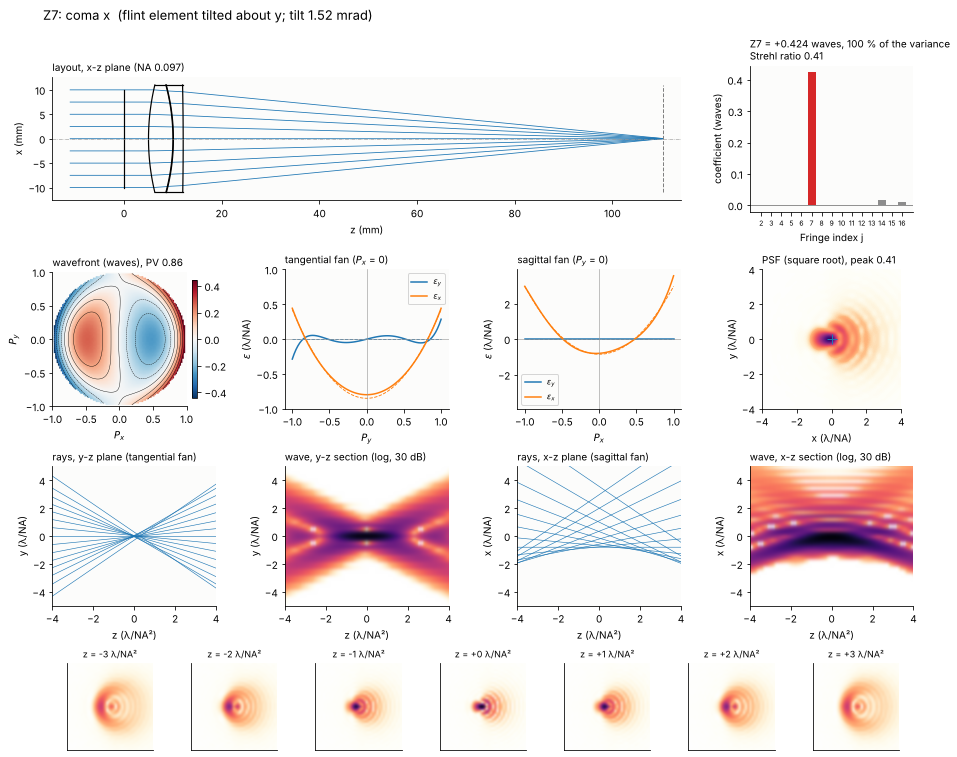

In [10]:
a_y, s = tune(lambda a: refocus(achromat(flint_tilt=(0.0, a, 0.0), back=BACK)), 7, 1e-5, 0.05)
fig = gallery(7, s, "flint element tilted about y", "tilt {:.2f} mrad".format(a_y*1e3), plane="xz")

**Z8: the flint element decentred in y.** The same coma in y comes from a
decentre of the flint element of a few tens of µm, an ordinary tolerance
for a lens in a cell without centring.

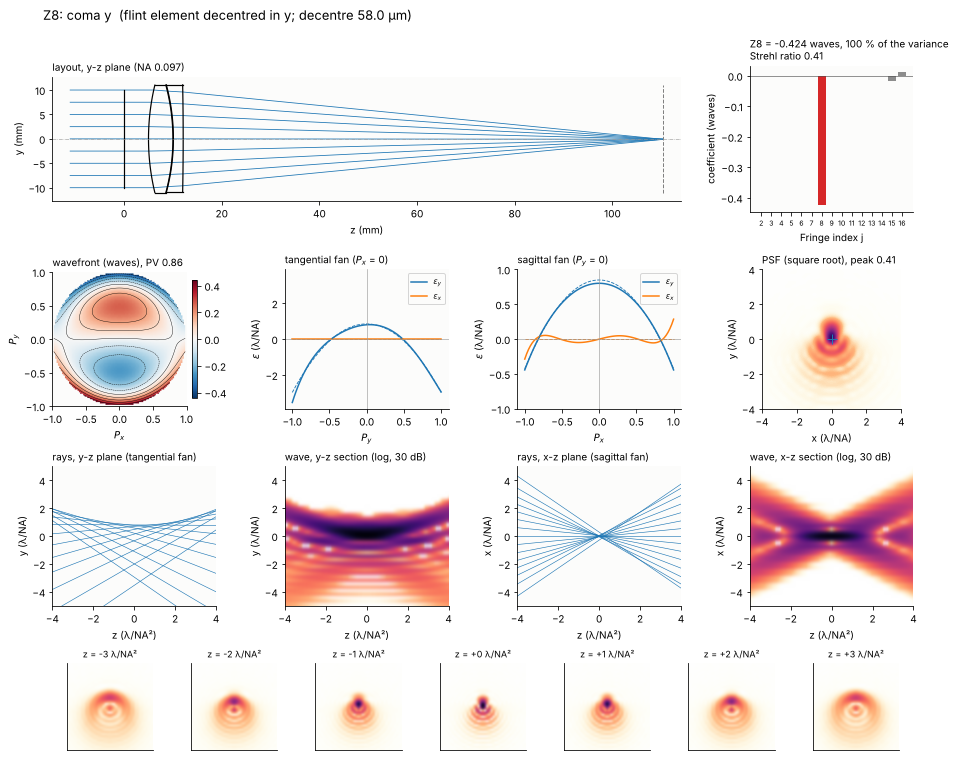

In [11]:
d8, s = tune(lambda d: refocus(achromat(flint_decenter=(0.0, d), back=BACK)), 8, 1e-4, 1.0)
fig = gallery(8, s, "flint element decentred in y", "decentre {:.1f} µm".format(d8*1e3))

## 8. Spherical aberration (Z9)

A plano-convex singlet of the same 100 mm focal length, the wrong way
round (plane side towards the collimated beam), has about four times the
spherical aberration of the right orientation (notebook 19). Spherical
aberration grows with the fourth power of the aperture, so the singlet is
stopped down to reach 0.34 waves of Z9 at the best focus. The rim rays
focus in front of the paraxial focus (undercorrected, W040 < 0). The
Fringe Z9 contains the defocus $-6\rho^2$ that puts the image plane
between the marginal and the paraxial focus.

The ray fan is the cubic $\varepsilon \propto 4\rho^3 - 2\rho$ (rays
relative to the best focus), the same in both sections. The through focus
series shows the classic asymmetry of the star test: towards the lens
(negative z) the defocused spot is a wide disk with a sharp bright rim,
behind the focus a compact core in a soft halo. In the sections the
caustic of the marginal rays runs from the marginal focus (left) to the
cusp at the paraxial focus (right). Spherical aberration is the only term
of the gallery with this asymmetry, together with Z16: for the terms with
$m \neq 0$, $-W$ is $W$ turned by $180°/m$, so the spots in front of and
behind the focus are the same (odd m: tilt, coma, trefoil, secondary coma)
or the same turned by 90° (m = 2: astigmatism and secondary astigmatism).

Seidel W040 -1.99 waves (paraxial focus), 6 Z9 = -2.01 waves


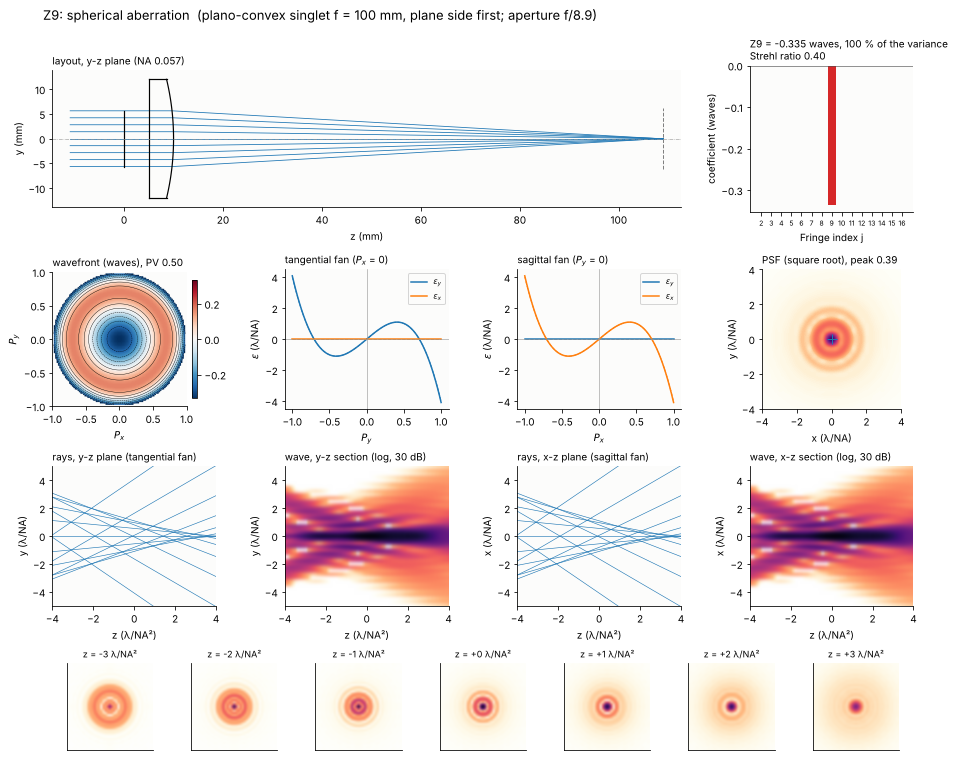

In [12]:
def plano_convex(epr):
    R = 100.0*(BK7[0] - 1)
    surfaces = [rt.Surface(np.inf, 5.0, semi_diameter=epr, label="stop"),
                rt.Surface(np.inf, 5.0, material=BK7, semi_diameter=12.0, label="BK7"),
                rt.Surface(-R, 95.0, n_after=1.0, semi_diameter=12.0)]
    return refocus(rt.System(surfaces, 0, WL).at_paraxial_focus())


epr9, s = tune(plano_convex, 9, 2.0, 10.0)
fig = gallery(9, s, "plano-convex singlet f = 100 mm, plane side first",
              "aperture f/{:.1f}".format(100.0/(2*epr9)))
print("Seidel W040 {:+.2f} waves (paraxial focus), 6 Z9 = {:+.2f} waves".format(
    s.at_paraxial_focus().seidel(0.0).W040, 6*RESULTS[9]["c"]))

## 9. Trefoil (Z10, Z11)

Trefoil $\rho^3\cos 3\theta$ has a threefold symmetry that no rotationally
symmetric lens has, misaligned or not, at least not in third order. (At the
edge of the field of a lens the fifth order "elliptical coma"
$\propto \cos^3\theta$ contains a trefoil part, but always together with
much larger coma.) The everyday source of trefoil is mechanical: a mirror
or a window held at three points, or bent by the three screws of its
mount, deforms with threefold symmetry (Yoder). The window here is a 3 mm
BK7 plate in front of the achromat whose front face is bent by its three
point mount into the shape $c\,Z_{10}$, modelled with
`raytrace.ZernikeSurface` (a surface with a Fringe Zernike departure from
its base sphere, Zemax's "Zernike Fringe Sag"). A surface departure $c$ of
a window in transmission changes the OPD by $-(n - 1)c$; in reflection a
mirror doubles it, $2c$.

The trefoil PSF has three tails, the ray fans are parabolas with the sign
of the three lobes. Along both axes of the pupil the rays of Z10 are
deflected in x only: $\varepsilon_x = 3c(P_x^2 - P_y^2)$, a parabola of
opposite sign in the tangential and the sagittal fan, while
$\varepsilon_y = -6cP_xP_y$ vanishes on both fans (for Z11 the components
swap). The through focus series is symmetric about the focus: the
triangular spot keeps its orientation and grows on both sides.

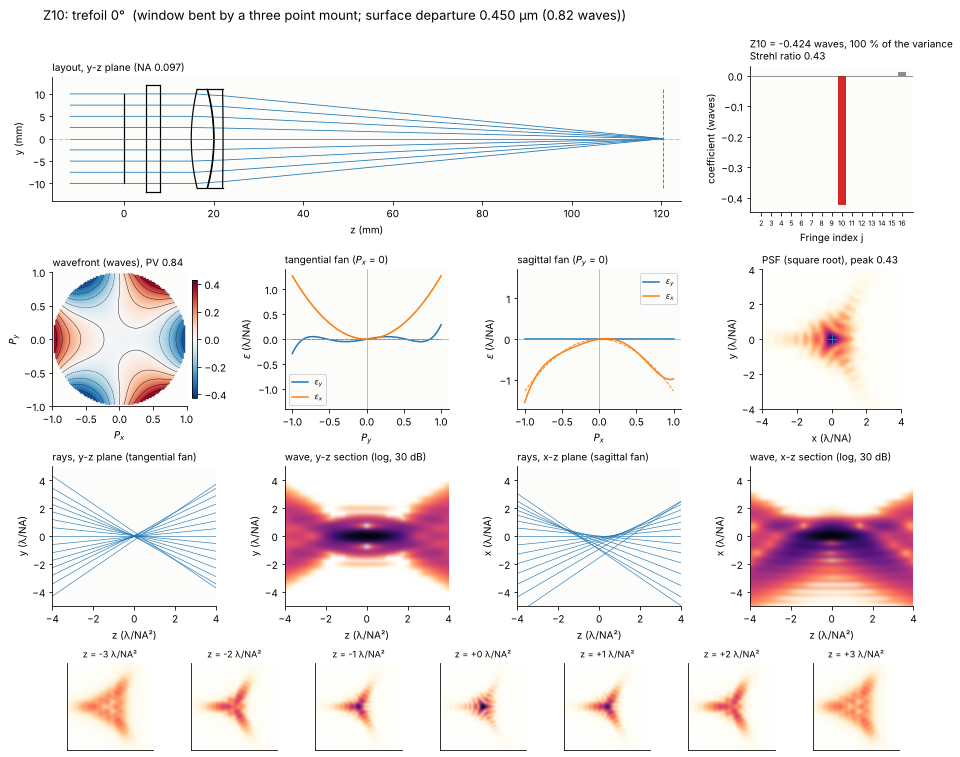

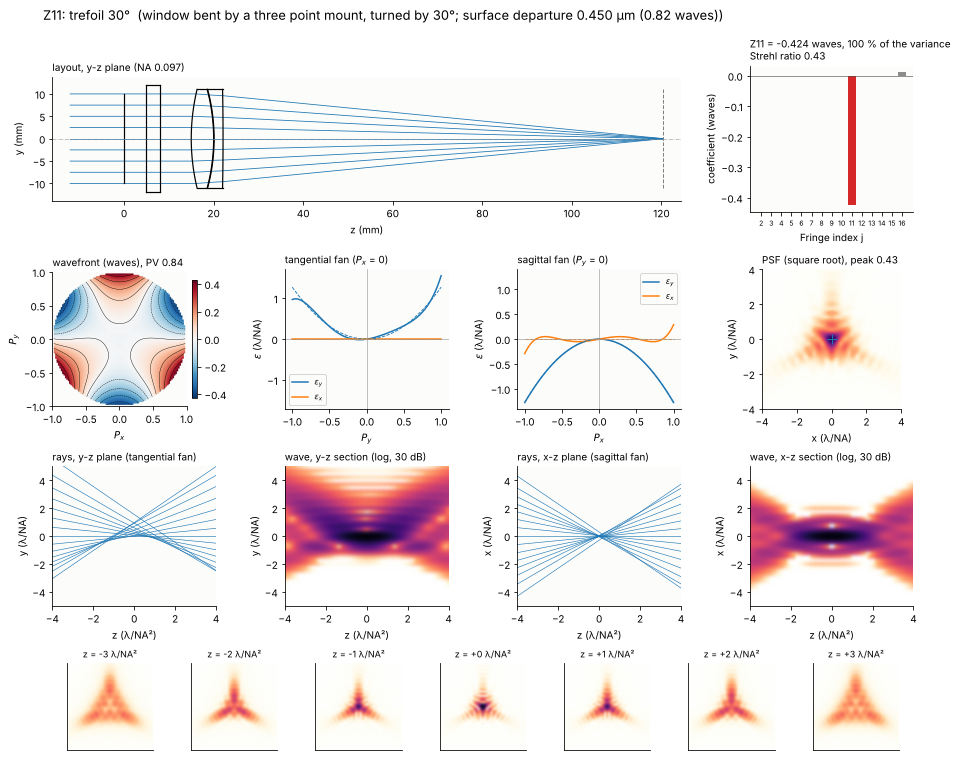

In [13]:
def window(j, amplitude):
    w = [rt.ZernikeSurface(np.inf, 3.0, material=BK7, semi_diameter=12.0, zernike={j: amplitude},
                           norm_radius=EPR, label="window"),
         rt.Surface(np.inf, 7.0, n_after=1.0, semi_diameter=12.0)]
    return achromat(before=w, back=BACK)


for j in (10, 11):
    amp, s = tune(lambda a: window(j, a), j, 1e-6, 1e-3)
    fig = gallery(j, s, "window bent by a three point mount" + (", turned by 30°" if j == 11 else ""),
                  "surface departure {:.3f} µm ({:.2f} waves)".format(amp*1e3, amp/WL))
    plt.show()

## 10. Secondary astigmatism (Z12, Z13)

Secondary astigmatism $(4\rho^4 - 3\rho^2)\cos 2\theta$ is a fifth order
term. In lens designs it appears at the edge of the field (oblique spherical
aberration $\propto \rho^4\cos^2\theta$), next to primary astigmatism, and it
cannot be produced alone by a decentre or tilt of spherical elements. It is
a common figure error, however: a window or mirror clamped across a diameter
bends astigmatically, and once the low order astigmatism is compensated in
the alignment (by clocking another element) or polished out, the secondary
part remains. The window of the previous entry carries a departure
$c\,Z_{12}$, then $c\,Z_{13}$.

The ray fans are cubics of opposite sign in the two sections (Z12) or in
the cross components (Z13). In focus the core is surrounded by four lobes
on the axes (Z12) or the diagonals (Z13); on either side of the focus the
spot stretches into a row of lobes, along x on one side and along y on the
other, like astigmatism with a finer structure.

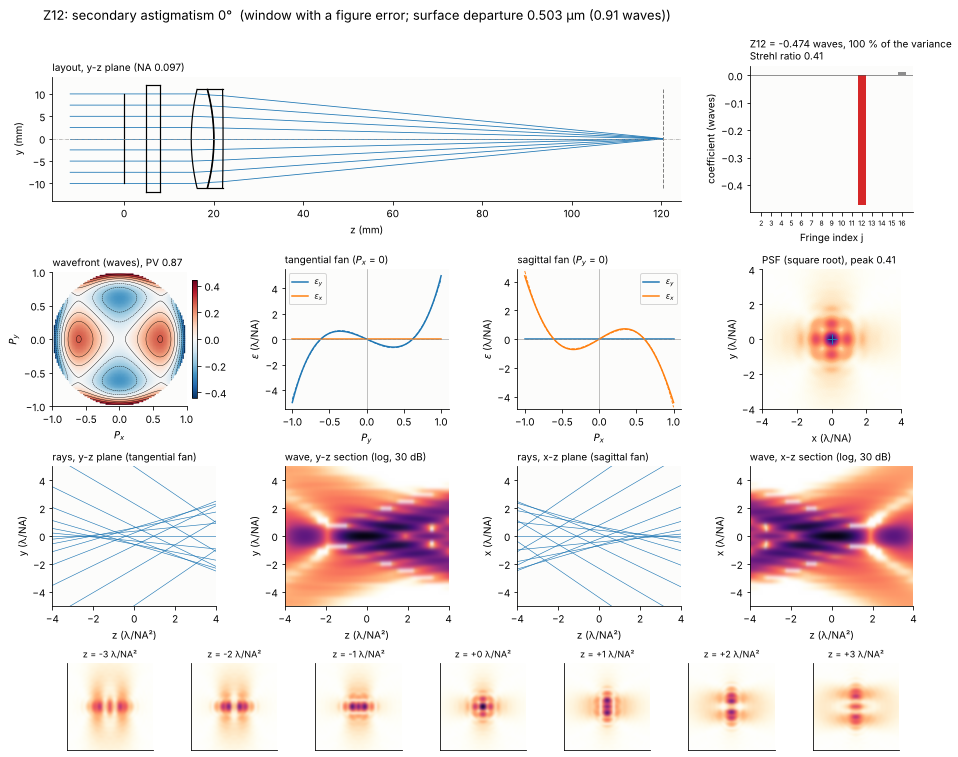

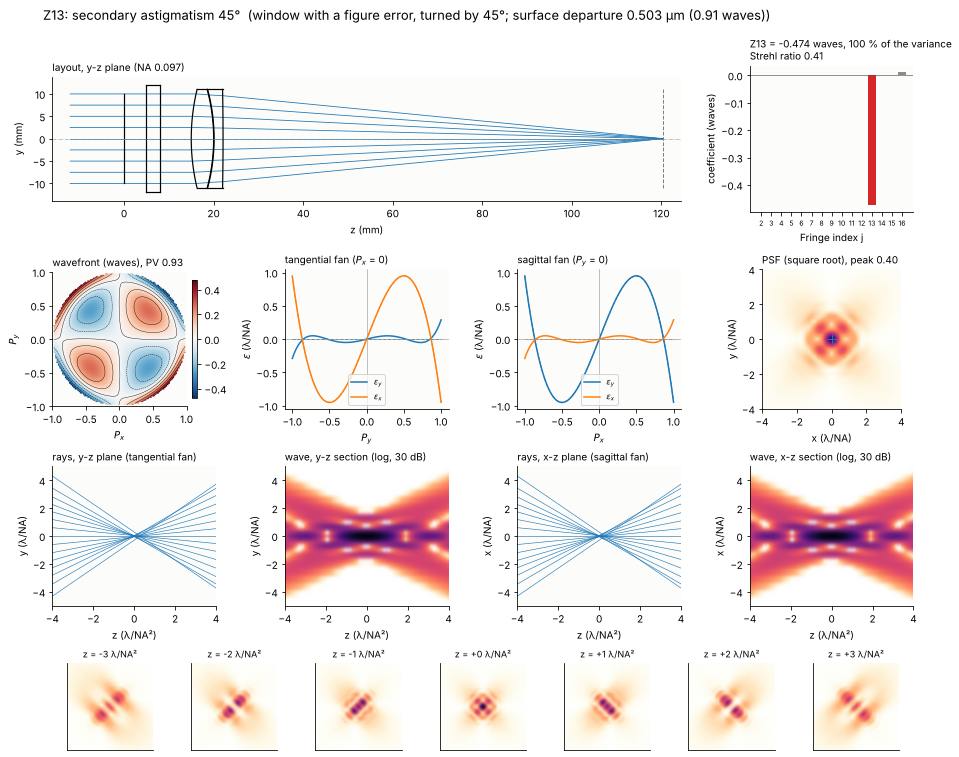

In [14]:
for j in (12, 13):
    amp, s = tune(lambda a: window(j, a), j, 1e-6, 1e-3)
    fig = gallery(j, s, "window with a figure error" + (", turned by 45°" if j == 13 else ""),
                  "surface departure {:.3f} µm ({:.2f} waves)".format(amp*1e3, amp/WL))
    plt.show()

## 11. Secondary spherical aberration (Z16)

A spherical lens has spherical aberration of all orders,
$W = a_4\rho^4 + a_6\rho^6 + \dots$, with the higher orders growing faster
with the aperture. A fourth order asphere ($A_4 r^4$ on the front face)
removes $Z_9$, i.e. balances $a_4$ against the $\rho^4$ part of the higher
orders; what remains is the secondary (zonal) spherical aberration $Z_{16}$.
It is the characteristic residual of corrected fast lenses: the marginal
and paraxial rays meet in one focus, the zone in between does not. The
lens is a plano-convex BK7 singlet of 20 mm focal length; at f/2 (NA 0.25)
it reaches 0.4 waves of Z16 (with $A_4$ solved for Z9 = 0 at every
aperture).

The ray fan is the quintic $\partial Z_{16}/\partial\rho = 120\rho^5 -
120\rho^3 + 24\rho$: the rays of the centre and of the zones at
$\rho$ = 0.53 and 0.85 pass the best focus, those in between and at the rim
miss it, the rim rays by $24c$ λ/NA. Like Z9 it is not symmetric through
focus: on one side a sharp core in many rings, on the other a weaker core
inside a bright ring.

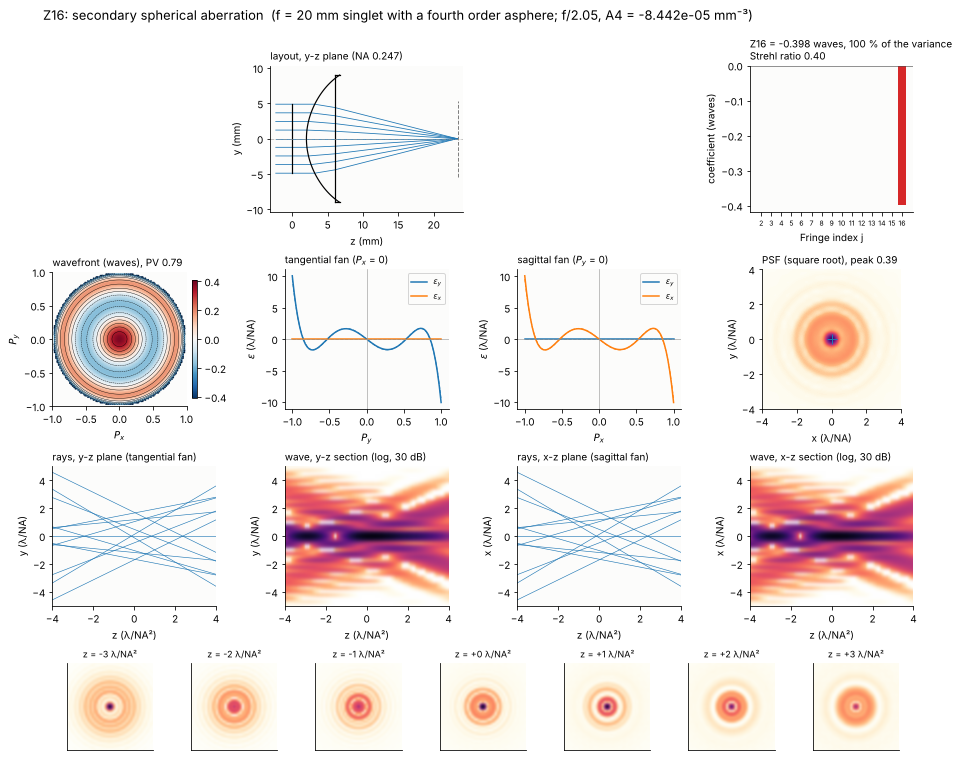

In [15]:
F_ASPH, T_ASPH = 20.0, 4.0


def singlet_surfaces(A4, A6=0.0):
    R = F_ASPH*(BK7[0] - 1)
    return [rt.Surface(R, T_ASPH, material=BK7, semi_diameter=9.0, aspheric=(A4, A6), label="asphere"),
            rt.Surface(np.inf, F_ASPH - T_ASPH/BK7[0], n_after=1.0, semi_diameter=9.0)]


def aspheric_singlet(epr, A4):
    surfaces = [rt.Surface(np.inf, 2.0, semi_diameter=epr, label="stop")] + singlet_surfaces(A4)
    return refocus(rt.System(surfaces, 0, WL).at_paraxial_focus())


def corrected_singlet(epr):
    A4 = brentq(lambda a: aspheric_singlet(epr, a).zernike(0.0, 16, 32)[8], -2e-4, 0.0, xtol=1e-12)
    return aspheric_singlet(epr, A4), A4


epr16, s = tune(lambda e: corrected_singlet(e)[0], 16, 3.0, 6.0)
A4 = corrected_singlet(epr16)[1]
fig = gallery(16, s, "f = 20 mm singlet with a fourth order asphere",
              "f/{:.2f}, A4 = {:.3e} mm⁻³".format(F_ASPH/(2*epr16), A4))

## 12. Secondary coma (Z14, Z15)

Decentring an element that corrects spherical aberration gives coma (Z8
above). Decentring an element that corrects secondary spherical aberration
gives secondary coma, but in general together with primary coma: the
decentre $\delta$ adds $\delta\,\partial W_c/\partial y$ of the correction
$W_c$ of the element, and
$\partial Z_{16}/\partial y = 12 Z_{15} + 8 Z_8 + 4 Z_3$,
$\partial Z_9/\partial y = 8 Z_8 + 4 Z_3$. The primary coma cancels if the
corrector removes $Z_9$ and $Z_{16}$ in the ratio $-1$, i.e. the shape
$Z_{16} - Z_9$.

The lens: the f = 20 mm singlet at f/1.67 (NA 0.3), with its asphere
chosen such that it has Z9 = −Z16, and in front of it a Schmidt type
corrector plate (BK7, with $r^4$ and $r^6$ terms on its front face) that
removes both. The corrected lens is diffraction limited (Strehl 0.96, the
rest is spherical aberration of seventh and higher order);
decentring the corrector in x and y gives Z14 and Z15. Second order
effects of the decentre (Z9, Z12) remain small.

The PSF is a bright core in a comet shaped system of arcs. The tangential
fan is the quartic $\varepsilon_y = c\,(50P_y^4 - 36P_y^2 + 3)$ (relative to
the best focus), the sagittal one $\varepsilon_y = c\,(10P_x^4 - 12P_x^2 + 3)$.

singlet alone: Z9 +1.696, Z16 -1.696 waves; corrector A4 = 5.010e-05, A6 = -7.459e-07; corrected lens: Strehl 0.9633


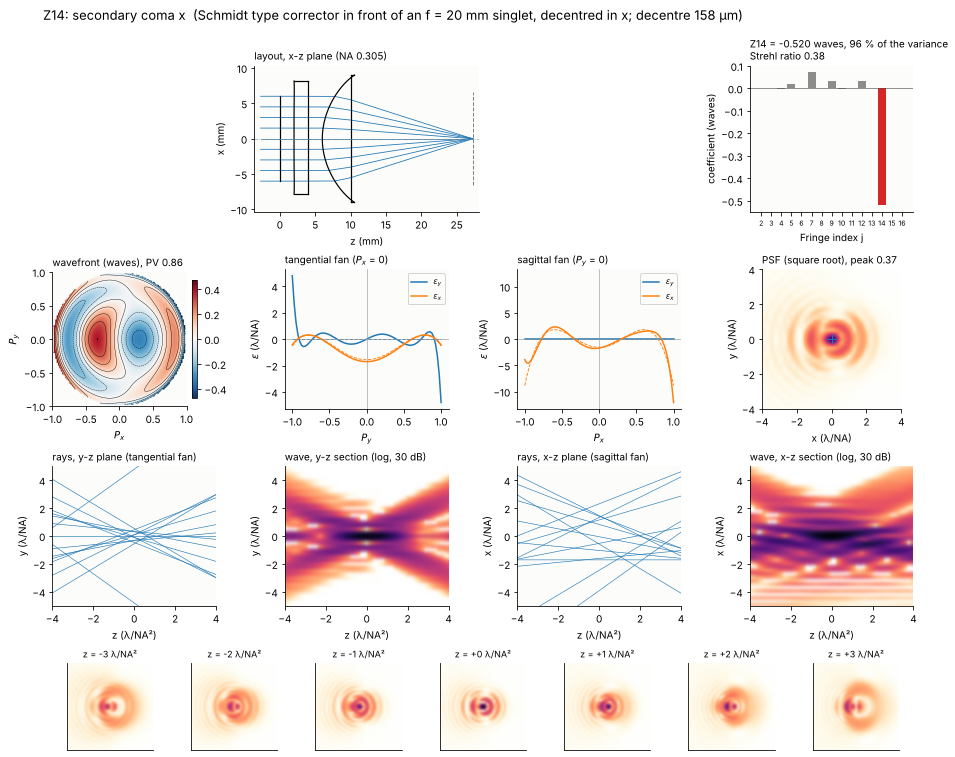

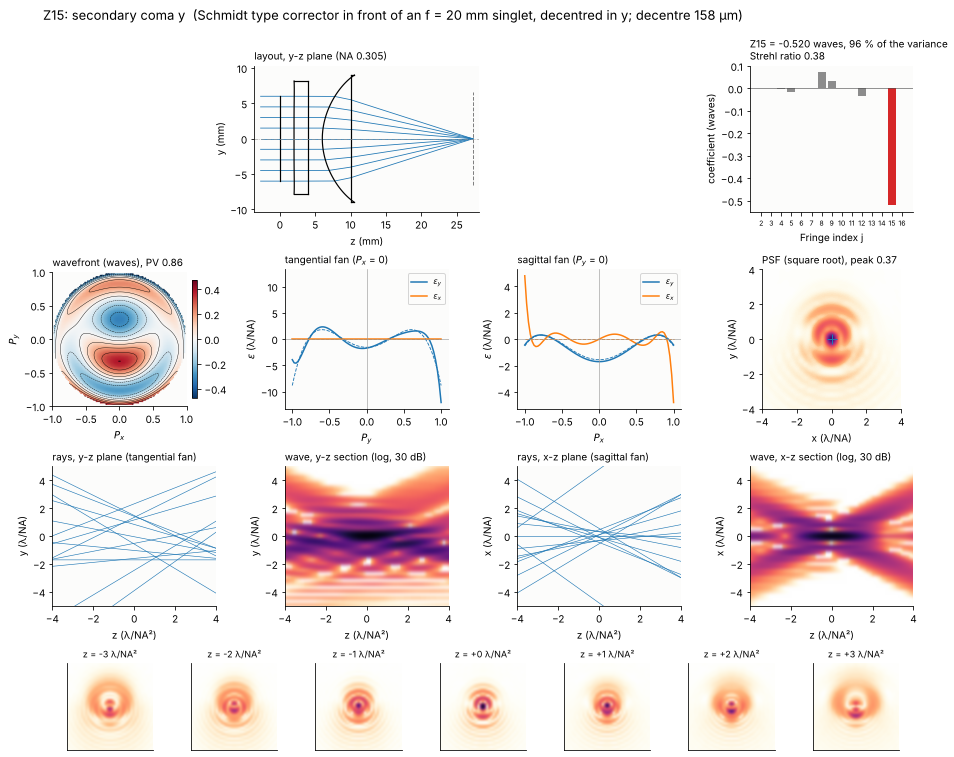

In [16]:
EPR_SC = 6.0


def schmidt(A4_lens, P=(0.0, 0.0), decenter=(0.0, 0.0)):
    corrector = [rt.Surface(np.inf, 2.0, material=BK7, semi_diameter=8.0, aspheric=P, decenter=decenter,
                            label="corrector"),
                 rt.Surface(np.inf, 2.0, n_after=1.0, semi_diameter=8.0, decenter=decenter)]
    surfaces = [rt.Surface(np.inf, 2.0, semi_diameter=EPR_SC, label="stop")] + corrector + singlet_surfaces(A4_lens)
    return refocus(rt.System(surfaces, 0, WL).at_paraxial_focus())


A4_sc = brentq(lambda a: (lambda c: c[8] + c[15])(schmidt(a).zernike(0.0, 16, 48)), -3e-4, 0.0, xtol=1e-12)
c_lens = schmidt(A4_sc).zernike(0.0, 16, 48)
P_sc = fsolve(lambda q: schmidt(A4_sc, (q[0]*1e-5, q[1]*1e-7)).zernike(0.0, 16, 48)[[8, 15]], [3.0, -10.0])
P_sc = (P_sc[0]*1e-5, P_sc[1]*1e-7)
corrected = schmidt(A4_sc, P_sc)
print("singlet alone: Z9 {:+.3f}, Z16 {:+.3f} waves; corrector A4 = {:.3e}, A6 = {:.3e}; "
      "corrected lens: Strehl {:.4f}".format(c_lens[8], c_lens[15], *P_sc, corrected.strehl(0.0, 64)))

for j, axis in ((14, 0), (15, 1)):
    dec = lambda d: schmidt(A4_sc, P_sc, (d, 0.0) if axis == 0 else (0.0, d))
    d, s = tune(dec, j, 1e-3, 1.0)
    fig = gallery(j, s, "Schmidt type corrector in front of an f = 20 mm singlet, decentred in " + "xy"[axis],
                  "decentre {:.0f} µm".format(d*1e3), plane="xz" if axis == 0 else "yz")
    plt.show()

## 13. Overview

All lenses with their main term, its share of the wavefront variance and
the Strehl ratio (tilt removed). Equal RMS gives Strehl ratios close to the
Maréchal value of 0.41 (exp(−(2π·0.15)²)); the exact value
$|\langle e^{2\pi i W}\rangle|^2$ depends on the shape of the term. The
misaligned and uncorrected lenses give their term with 95 % of the
wavefront variance or more; trefoil and secondary astigmatism are pure by
construction. The PSFs of the lenses (in the image plane, about the
reference point) next to each other: compare with the pure terms of
section 1.

     term                             lens                                                               coeff.   share  Strehl     NA
Z2   tilt x                           3 mm BK7 wedge in front of the achromat                            -1.000  100.0%    1.00  0.097
Z3   tilt y                           achromat decentred in y                                            +1.000  100.0%    1.00  0.097
Z4   defocus                          achromat, image plane behind the focus                             -0.260   99.9%    0.38  0.097
Z5   astigmatism 0°                   2 mm plate tilted about x, 50 mm behind the lens                   -0.367   97.1%    0.40  0.097
Z6   astigmatism 45°                  the plate tilted towards 45°                                       -0.367   97.1%    0.40  0.097
Z7   coma x                           flint element tilted about y                                       +0.424   99.8%    0.41  0.097
Z8   coma y                           flint element dec

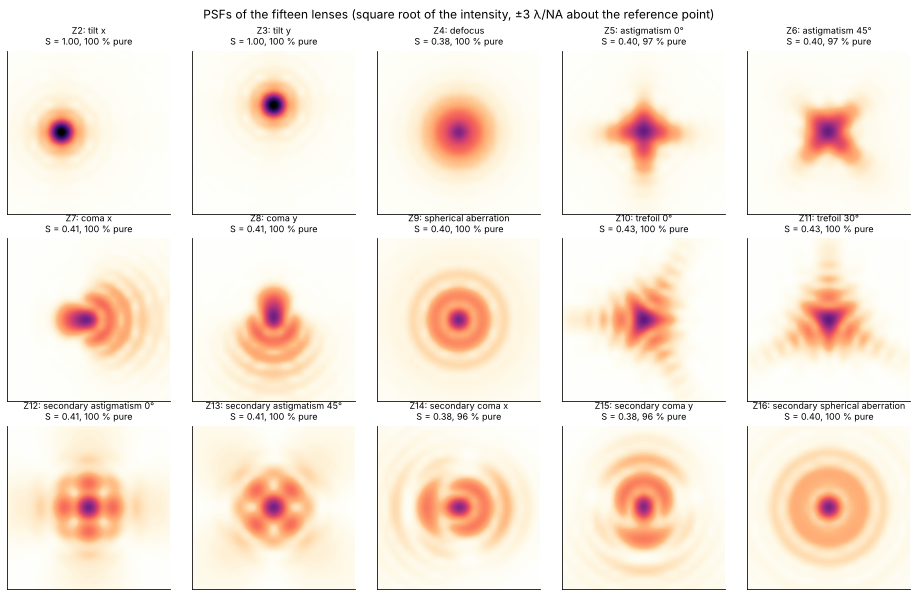

In [17]:
print("{:4s} {:32s} {:64s} {:>8s} {:>7s} {:>7s} {:>6s}".format("", "term", "lens", "coeff.", "share",
                                                               "Strehl", "NA"))
for j in range(2, 17):
    r = RESULTS[j]
    print("Z{:<3d} {:32s} {:64s} {:+8.3f} {:6.1f}% {:7.2f} {:6.3f}".format(
        j, NAMES[j], r["situation"][:64], r["c"], 100*r["share"], r["strehl"], r["NA"]))

fig, axes = plt.subplots(3, 5, figsize=(13, 8.4))
for ax, j in zip(axes.flat, range(2, 17)):
    s_j = RESULTS[j]
    ax.set_title("Z{}: {}\nS = {:.2f}, {:.0f} % pure".format(j, NAMES[j], s_j["strehl"], 100*s_j["share"]),
                 fontsize=9)
    ax.set_xticks([]), ax.set_yticks([])
    ux, uy, I0 = s_j["psf"]
    ax.imshow(np.sqrt(I0), extent=[ux[0], ux[-1], uy[0], uy[-1]], cmap=light, vmin=0, vmax=0.8,
              interpolation="bicubic")
    ax.set_xlim(-3, 3), ax.set_ylim(-3, 3)
plt.suptitle("PSFs of the fifteen lenses (square root of the intensity, ±3 λ/NA about the reference point)")
plt.tight_layout()
print("run time {:.0f} s".format(time.time() - t_start))

## Summary

- Low order Zernikes have simple physical causes: a wedge or a decentred
  lens (tilt), a misplaced image plane (defocus), a tilted plate in a
  converging beam (astigmatism), a decentred or tilted element of a
  corrected lens (coma), an uncorrected singlet (spherical aberration).
- Coma comes from misaligned elements that carry spherical aberration of
  their own; a lens without spherical aberration can be decentred as a whole
  without coma.
- The fifth order terms are residuals of corrected lenses: secondary
  spherical aberration of a fast aspheric singlet, secondary coma of a
  decentred corrector (pure only if the corrector removes $Z_{16} - Z_9$).
- Trefoil and secondary astigmatism do not come from a misaligned
  rotationally symmetric lens at low order; they are mount deformations and
  figure errors, here modelled with `raytrace.ZernikeSurface`.
- Through focus, only the rotationally symmetric terms (Z4 aside: Z9,
  Z16) differ in front of and behind the focus; the spots of the other
  terms are the same on both sides (odd m) or turned by 90° (m = 2).
- In units of $\lambda/\mathrm{NA}$ the ray fans are the slopes of the
  wavefront in waves per pupil radius; the traced fans follow the slope of
  the main term wherever the wavefront is pure.
- Ray picture and wave picture agree on the large scale (the caustics of
  spherical aberration and coma, the line foci of astigmatism), the wave
  field adds the interference fringes and the finite size of the focus.

## References

- F. Zernike, "Beugungstheorie des Schneidenverfahrens und seiner verbesserten Form, der Phasenkontrastmethode", Physica 1, 689-704 (1934).
- R. J. Noll, "Zernike polynomials and atmospheric turbulence", J. Opt. Soc. Am. 66, 207-211 (1976).
- J. C. Wyant and K. Creath, "Basic wavefront aberration theory for optical metrology", in R. R. Shannon and J. C. Wyant (eds.), *Applied Optics and Optical Engineering*, Vol. XI, Academic Press (1992), pp. 1-53.
- D. Malacara (ed.), *Optical Shop Testing*, 3rd ed., Wiley (2007).
- W. T. Welford, *Aberrations of Optical Systems*, Adam Hilger (1986).
- V. N. Mahajan, *Optical Imaging and Aberrations, Part I: Ray Geometrical Optics*, SPIE Press (1998), and *Part II: Wave Diffraction Optics*, 2nd ed., SPIE Press (2011).
- M. Born and E. Wolf, *Principles of Optics*, 7th ed., Cambridge University Press (1999).
- W. J. Smith, *Modern Optical Engineering*, 4th ed., McGraw-Hill (2008).
- K. P. Thompson, "Description of the third-order optical aberrations of near-circular pupil optical systems without symmetry", J. Opt. Soc. Am. A 22, 1389-1401 (2005).
- P. R. Yoder, *Opto-Mechanical Systems Design*, 3rd ed., CRC Press (2006).
- B. Schmidt, "Ein lichtstarkes komafreies Spiegelsystem", Mitteilungen der Hamburger Sternwarte in Bergedorf 7, 15-17 (1932).